In [7]:
import importlib
import re

In [18]:
importlib.reload(ps)

<module 'process_surveys' from 'C:\\GIT\\Parish-Survey\\2026\\process_surveys.py'>

In [2]:
import process_surveys as ps

In [4]:
ps.csv_to_excel_with_images("results/13-10-26 Consolidated Results.csv",
    excel_file=None,
    image_height=100)


WindowsPath('results/13-10-26 Consolidated Results.xlsx')

In [12]:
#figuring out the len of filenames

lens = list()
with open("pngs.txt", "r") as file:
    for line in file:
#        bits = line.split(" ")
        lens.append(len(line))

print (min(lens), max(lens))
sizes = dict()
for s in range(min(lens), max(lens)+1):
    sizes[s] = 0
    
for l in lens:
    sizes[l] += 1

print (sizes)

71 82
{71: 47, 72: 69, 73: 0, 74: 0, 75: 0, 76: 0, 77: 0, 78: 0, 79: 168, 80: 1375, 81: 1927, 82: 208}


In [27]:

from pathlib import Path

def find_file(filename, search_directory):
    for path in Path(search_directory).rglob(filename):
        if path.is_file():
            return str(path)

# caputure only filenames less than len 75 and with time starting from 14:00
lens = list()
search_dir = "C:\\Users\\BarryPrince\\OneDrive - Fabrum\\Desktop\\Temp\\"
with open("pngs.txt", "r") as r_file, open ("page_errors.csv", "w") as w_file:
    for line in r_file:
        if len(line) < 75:
            bits =  line.split(" ")
            if bits[1][:2] == "14":
                path = find_file(bits[2]+".pdf",search_dir)
                w_file.write(path + ", " + bits[3].split(".")[0] + "\n")

In [1]:
#check for corrupted PDF files
from pathlib import Path
from pypdf import PdfReader

def check_pdfs(list_file):
    list_file = Path(list_file)

    if not list_file.exists():
        print(f"ERROR: List file not found: {list_file}")
        return

    with open(list_file, "r", encoding="utf-8") as f:
        pdf_files = [line.strip() for line in f if line.strip()]
        
    print(f"Checking {len(pdf_files)} PDF files...\n")

    with open ("pdf_integrity.txt", "w") as out_file:
        for pdf_path in pdf_files:
            try:
                pdf_path = Path(pdf_path)
                
                if not pdf_path.exists():
                    raise FileNotFoundError("File does not exist")
                reader = PdfReader(str(pdf_path))
                page_count = len(reader.pages)
                print(f"OK | {page_count:4d} pages | {pdf_path}")
                out_file.write(f"OK | {page_count:4d} pages | {pdf_path}\n")
            except Exception as e:
                print(f"ERROR | {pdf_path} | {type(e).__name__}: {e}")
                out_file.write(f"ERROR | {pdf_path} | {type(e).__name__}: {e}\n")


In [8]:
check_pdfs("pdf_check.txt")

Checking 30 PDF files...

OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\10 am\doc20261010121842.pdf
OK |   42 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010125656.pdf
OK |   38 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010125814.pdf
OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010125953.pdf
OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010130158.pdf
OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010130328.pdf
OK |   42 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010130439.pdf
OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010130622.pdf
OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11 am\doc20261010130739.pdf
OK |   40 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp 2\11

In [12]:
with open("all_surveys.txt", "r", encoding="utf-8") as f:
    for line in f: 
        match = re.search(r'\\(T_[^\\]+)', line)
        batch = match.group(1)[2:]

10 am
11 am
11 am
11 am
11 am
11 am
11 am
11 am
11 am
11 am
11 am
11 am
11 am
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
5 pm
7 pm
Samoan
Samoan
Samoan
St B's


AttributeError: 'NoneType' object has no attribute 'group'

In [30]:
import sys

In [31]:
!"{sys.executable}" -m pip install openpyxl pillow

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [18]:
!"{sys.executable}" -m pip install pymupdf

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/19.8 MB ? eta -:--:--
   --- ------------------------------------ 1.6/19.8 MB 8.0 MB/s eta 0:00:03
   ------ --------------------------------- 3.1/19.8 MB 7.4 MB/s eta 0:00:03
   --------- ------------------------------ 4.7/19.8 MB 7.6 MB/s eta 0:00:02
   ------------ --------------------------- 6.0/19.8 MB 7.4 MB/s eta 0:00:02
   -------------- ------------------------- 7.1/19.8 MB 7.4 MB/s eta 0:00:02
   ----------------- ---------------------- 8.7/19.8 MB 7.0 MB/s eta 0:00:02
   -------------------- ------------------- 10.0/19.8 MB 6.8 MB/s eta 0:00:02
   ----------------------- ---------------- 11.8/19.8 MB 7.0 MB/s eta 0:00:02
   -------------------------- ------------- 13.4/19.8 MB 7.1 MB/s eta 0:00:01
   ------------------------------ --------- 14.9/19.8 MB 7.2 MB/s eta 0:00:01
   ------------------------------- -------- 15.7/19.8 MB 7.0 MB/s eta 0:00:01



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [2]:
import pdf_page_crop as c2p

png_data = c2p.crop_pdf_page_to_png(
    pdf_file="Test Surveys.pdf",
    page_number=1,
    crop_box=(0.25, 0.20, 0.75, 0.60),
    output_file="cropped_region.png",
)

In [33]:
#importlib.reload(ps)
import process_surveys as ps

In [37]:
output = ps.csv_to_excel_with_images(
    r"C:\GIT\Parish-Survey\2026\11-10-26 204230 Results of reprocessed page errors.csv"
)

print(output)

PNG not found on row 44: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 49: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 119: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 132: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 137: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 142: C:\GIT\Parish-Survey\2026\Text read error Found 4676 qualifying blue pixels
PNG not found on row 187: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 253: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 254: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 303: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 321: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 324: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 327: C:\GIT\Parish-Survey\2026\Multiple answers
PNG not found on row 336: C:\GIT\Parish-Survey\2026\Multiple answers
PNG

In [7]:
ps.read_blue_text(
    png_image="c:\\GIT\\Parish-Survey\\2026\\Q14 other.png",
    min_blue_pixels = 300,
    min_blue = 100,
    blue_margin = 30,
    tesseract_cmd=r"C:\Program Files\Tesseract-OCR\tesseract.exe")

'VA +a/ks'

In [95]:
ps.has_blue_pixels(
    png_file= "c:\\GIT\\Parish-Survey\\2026\\Q14 other.png",
    min_pixels= 2000)


True

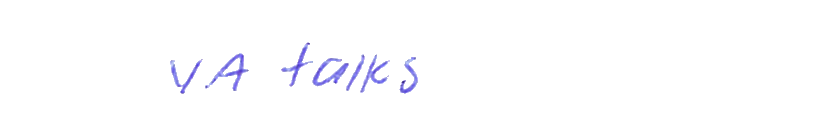

In [89]:
d = isolate_blue_pixels("c:\\GIT\\Parish-Survey\\2026\\Q14 other.png",100,30,"blue_only.png")
img = Image.open("blue_only.png")
display(img)

In [63]:
from IPython.display import Image, display
from pathlib import Path
from io import BytesIO

import numpy as np
from PIL import Image


def isolate_blue_pixels(
    png_file: str | Path,
    min_blue: int,
    blue_margin: int,
    output_file: str | Path | None = None,
) -> bytes:
    """
    Keep only pixels matching the specified RGB criteria.

    Pixels are retained if:
        blue >= min_blue
        red  <= max_red
        green <= max_green

    All other pixels are set to white.

    Returns:
        PNG image as bytes.
    """

    image = Image.open(png_file).convert("RGB")
    image_array = np.array(image)

    red = image_array[:, :, 0]
    green = image_array[:, :, 1]
    blue = image_array[:, :, 2]

    keep_mask = (
        (blue >= min_blue)
        & (blue - blue_margin > red )
        & (blue - blue_margin > green )
    )

    result = np.full_like(image_array, 255)  # white image
    result[keep_mask] = image_array[keep_mask]

    output_image = Image.fromarray(result)

    buffer = BytesIO()
    output_image.save(buffer, format="PNG")
    png_bytes = buffer.getvalue()

    if output_file is not None:
        Path(output_file).write_bytes(png_bytes)

    return png_bytes

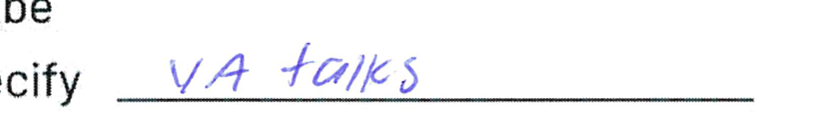

In [88]:
ps.crop_png("c:\\GIT\\Parish-Survey\\2026\\rectified_page_1.png",[
                        0.628726,
                        0.359628,
                        0.810692,
                        0.401505
                    ], "Q14 other.png")
img = Image.open("Q14 other.png")
display(img)

In [3]:

try:
    png_data, survey_number, page_code = ps.rectify_survey_page(
        pdf_file="Test Surveys.pdf",
        page_number=2,
        json_file="Survey_coords_7OCT.9.json",
        dpi=600,
        tesseract_cmd=r"C:\Program Files\Tesseract-OCR\tesseract.exe",
    )
    print("Survey number:", survey_number)
    print("Page code:", page_code)

except ps.BarcodeReadError as error:
    print("Barcode error:", error)

    # Save the barcode crop included with the error.
    error.save_barcode_crop("failed_barcode.png")

    # Alternatively:
    barcode_png_data = error.barcode_png

except ps.SurveyProcessingError as error:
    print("Page processing error:", error)

Barcode error: OCR did not produce exactly one four-digit survey number followed by P4 or P2; cleaned OCR text was 'P1978P1978PP2'


In [6]:
import sys
!"{sys.executable}" -m pip install pymupdf opencv-python numpy pytesseract

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ------- -------------------------------- 1.3/7.2 MB 6.6 MB/s eta 0:00:01
   ----------------- ---------------------- 3.1/7.2 MB 7.9 MB/s eta 0:00:01
   ------------------------ --------------- 4.5/7.2 MB 7.4 MB/s eta 0:00:01
   ---------------------------------- ----- 6.3/7.2 MB 7.6 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 7.2 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


In [8]:
check_pdfs("suvery_pdfs.txt")

NameError: name 'check_pdfs' is not defined

In [17]:
check_pdfs("suvery_pdfs.txt")

invalid pdf header: b'\xff\xff\xff\xff\xff'


Checking 155 PDF files...



EOF marker not found
invalid pdf header: b'\xff\xff\xff\xff\xff'


ERROR | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\blank 1.pdf | PdfStreamError: Stream has ended unexpectedly


EOF marker not found
invalid pdf header: b'\xff\xff\xff\xff\xff'


ERROR | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\blank 3.pdf | PdfStreamError: Stream has ended unexpectedly


... (114 outputs left out)

EOF marker not found


ERROR | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 10 am\doc20260922195427.pdf | PdfStreamError: Stream has ended unexpectedly
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203156.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203240.pdf
OK |   18 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203317.pdf
OK |   18 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203350.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203425.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203500.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203534.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922203607.pdf
OK |   20 pages | C:\Users\BarryPrince\OneD

EOF marker not found


ERROR | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 7 pm\doc20260922204311.pdf | PdfStreamError: Stream has ended unexpectedly
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922193844.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922193918.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922193947.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922194014.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922194041.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922194114.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922194141.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDrive - Fabrum\Desktop\Temp\St T 8 am\doc20260922194213.pdf
OK |   20 pages | C:\Users\BarryPrince\OneDr

In [100]:
import json

# Open the file in read mode ('r')
with open('Survey_coords_7OCT.7.json', 'r', encoding='utf-8') as file:
    data = json.load(file)

# The data is now parsed into a Python dictionary or list
print(data)

{'coordinate_system': {'Page Coordinate': {'scope': 'full A3 landscape page', 'origin': 'top_left', 'page_corners': {'top_left': [0.0, 0.0], 'top_right': [1.0, 0.0], 'bottom_left': [0.0, 1.0], 'bottom_right': [1.0, 1.0]}, 'x_axis': 'left_to_right', 'y_axis': 'top_to_bottom', 'box_order': ['x1', 'y1', 'x2', 'y2'], 'alignment_search_boxes': {'top_left_square': [0.0067, 0.0179, 0.055, 0.0667], 'top_right_square': [0.9372, 0.0179, 0.9854, 0.0667], 'bottom_left_square': [0.0067, 0.9269, 0.055, 0.9758], 'bottom_right_square': [0.9372, 0.9269, 0.9854, 0.9758], 'top_centre_triangle': [0.4794, 0.025406, 0.5226, 0.071599], 'bottom_centre_triangle': [0.4794, 0.936698, 0.5226, 0.98546]}}, 'Alignment Coordinate': {'scope': 'Inside corners of the four alignment squares', 'origin': 'top_left', 'corners': {'top_left': [0, 0], 'top_right': [1, 0], 'bottom_left': [0, 1], 'bottom_right': [1, 1]}, 'box_order': ['x1', 'y1', 'x2', 'y2'], 'geometry': 'sheet-specific projective transform'}}, 'questions': [{'i

In [81]:
# Open the file in read mode ('r')
with open('survey_read_info.txt', 'r', encoding='utf-8') as file:
    labels = json.load(file)

# The data is now parsed into a Python dictionary or list
print(labels)

{'schema_version': '1.0', 'source_file': 'blank 3.pdf', 'survey_name': 'Holy Family Parish Bi-Annual Parish Survey', 'coordinate_system': {'type': 'normalised_logical_page', 'origin': 'top_left', 'x_range': [0.0, 1.0], 'y_range': [0.0, 1.0], 'box_order': ['x1', 'y1', 'x2', 'y2'], 'page_definition': 'Each physical A3 side is corrected for rotation/scale and split into two logical portrait pages. Coordinates below apply after that correction and splitting.', 'important': 'Coordinates are template-level seed regions and should be refined against the original-resolution scan before production OMR. Convert to pixels with x_px=x_norm*page_width_px and y_px=y_norm*page_height_px.'}, 'physical_sheet': {'paper': 'A3', 'logical_pages_per_survey': 4, 'registration_marks': {'corner_squares': [{'id': 'top_left', 'box': [0.01, 0.01, 0.07, 0.055]}, {'id': 'top_right', 'box': [0.93, 0.01, 0.99, 0.055]}, {'id': 'bottom_left', 'box': [0.01, 0.945, 0.07, 0.99]}, {'id': 'bottom_right', 'box': [0.93, 0.945

In [99]:
data['coordinate_system']['Page Coordinate'].keys()

dict_keys(['scope', 'origin', 'page_corners', 'x_axis', 'y_axis', 'box_order', 'alignment_search_boxes'])

In [83]:
labels.keys()

dict_keys(['schema_version', 'source_file', 'survey_name', 'coordinate_system', 'physical_sheet', 'question_types', 'questions', 'validation_rules'])

In [84]:
labels["questions"]

[{'id': 'Q1',
  'page': 1,
  'type': 'single',
  'text': 'How long have you been coming to Mass at Holy Family Parish?',
  'inputs': [{'kind': 'circle',
    'option': 'Less than 2 years',
    'box': [0.07, 0.448, 0.091, 0.466]},
   {'kind': 'circle',
    'option': 'Between 2-10 years',
    'box': [0.07, 0.474, 0.091, 0.492]},
   {'kind': 'circle',
    'option': 'Between 20-30 years',
    'box': [0.07, 0.5, 0.091, 0.518]},
   {'kind': 'circle',
    'option': 'I am a visitor / do not usually attend Mass at this Parish',
    'box': [0.07, 0.526, 0.091, 0.544]},
   {'kind': 'circle',
    'option': 'Between 11-20 years',
    'box': [0.378, 0.474, 0.399, 0.492]},
   {'kind': 'circle',
    'option': 'More than 30 years',
    'box': [0.378, 0.5, 0.399, 0.518]}]},
 {'id': 'Q2',
  'page': 1,
  'type': 'single',
  'text': 'If you have been attending Holy Family Parish for less than 2 years, which statement best describes you?',
  'inputs': [{'kind': 'circle',
    'option': 'I have started attendi

In [90]:
qs = list()
for t,s in zip(labels['questions'],data['questions']):
    if t['id'] == s['id']:
        s['text'] = t['text']
        print (f"{t['id']} done")
    else:
        print (f"{t['id']} not found")
    qs.append(s)
data['questions'] = qs

Q1 done
Q2 done
Q3 done
Q4 done
Q5a done
Q5b done
Q5c done
Q6 done
Q7 done
Q8 done
Q9 done
Q10a done
Q10b done
Q10c done
Q11 done
Q12 done
Q13 done
Q14 done
Q15 done
Q16 done
Q17 done
Q18 done
Q19 done
Q20 done
Q21 done
Q22 done
Q23 done
Q24 done
Q25 done
Q26 done
Q27 done


In [92]:
with open("Survey_coords_final.json", "w") as file:
    json.dump(data, file, indent=4)  # indent=4 makes it pretty and easy to read

In [91]:
data['questions']

[{'id': 'Q1',
  'sheet': 1,
  'type': 'single',
  'inputs': [{'kind': 'circle',
    'option_index': 1,
    'label': 'Less than 2 years',
    'alignment_box': [0.539839, 0.447684, 0.552501, 0.466047]},
   {'kind': 'circle',
    'option_index': 2,
    'label': 'Between 2-10 years',
    'alignment_box': [0.53989, 0.486326, 0.55255, 0.504682]},
   {'kind': 'circle',
    'option_index': 3,
    'label': 'Between 11-20 years',
    'alignment_box': [0.702199, 0.485762, 0.71485, 0.504121]},
   {'kind': 'circle',
    'option_index': 4,
    'label': 'Between 20-30 years',
    'alignment_box': [0.539917, 0.506608, 0.552576, 0.524961]},
   {'kind': 'circle',
    'option_index': 5,
    'label': 'More than 30 years',
    'alignment_box': [0.702212, 0.50653, 0.714862, 0.524886]},
   {'kind': 'circle',
    'option_index': 6,
    'label': 'I am a visitor / do not usually attend Mass at this Parish',
    'alignment_box': [0.539975, 0.550539, 0.552631, 0.568885]}],
  'text': 'How long have you been coming

In [77]:
data['barcodes']

[{'logical_page': 'P4',
  'sheet': 1,
  'alignment_box': [0.209474, 0.980772, 0.270905, 1.011536]},
 {'logical_page': 'P1',
  'sheet': 1,
  'alignment_box': [0.740349, 0.980762, 0.802768, 1.011541]},
 {'logical_page': 'P2',
  'sheet': 2,
  'alignment_box': [0.207496, 0.98242, 0.269041, 1.013326]},
 {'logical_page': 'P3',
  'sheet': 2,
  'alignment_box': [0.73776, 0.9809, 0.79824, 1.011796]}]

In [32]:
data["coordinate_system"].keys()

dict_keys(['Page Coordinate', 'Alignment Coordinate'])

In [78]:
new_j = data.copy()

In [62]:
bcs = list()
for bc in data['barcodes']:
    nbc = dict()
    nbc['logical_page'] = bc['logical_page']
    nbc['sheet'] = bc['sheet']
    nbc['alignment_box'] = bc['alignment_box']    
    bcs.append(nbc)
new_j['barcodes'] = bcs
    

In [66]:
qs = list()
for q in data['questions']:
    nq = dict()
    nq['id'] = q['id']
    nq['question'] = 
    nq['sheet'] = q['sheet']
    nq['type'] = q['type']   
    inputs = list()
    for i in q['inputs']:
        ni = dict()
        ni['kind'] = i['kind']
        if i['kind'] ==  'circle':
            ni['option_index'] = i['option_index']
        ni['label'] = ''
        ni['alignment_box'] = i['alignment_box']
        inputs.append(ni)
    nq['inputs'] = inputs    
    qs.append(nq)
new_j['questions'] = qs

In [67]:
new_j['questions']

[{'id': 'Q1',
  'sheet': 1,
  'type': 'single',
  'inputs': [{'kind': 'circle',
    'option_index': 1,
    'label': '',
    'alignment_box': [0.539839, 0.447684, 0.552501, 0.466047]},
   {'kind': 'circle',
    'option_index': 2,
    'label': '',
    'alignment_box': [0.53989, 0.486326, 0.55255, 0.504682]},
   {'kind': 'circle',
    'option_index': 3,
    'label': '',
    'alignment_box': [0.702199, 0.485762, 0.71485, 0.504121]},
   {'kind': 'circle',
    'option_index': 4,
    'label': '',
    'alignment_box': [0.539917, 0.506608, 0.552576, 0.524961]},
   {'kind': 'circle',
    'option_index': 5,
    'label': '',
    'alignment_box': [0.702212, 0.50653, 0.714862, 0.524886]},
   {'kind': 'circle',
    'option_index': 6,
    'label': '',
    'alignment_box': [0.539975, 0.550539, 0.552631, 0.568885]}]},
 {'id': 'Q2',
  'sheet': 1,
  'type': 'single',
  'inputs': [{'kind': 'circle',
    'option_index': 1,
    'label': '',
    'alignment_box': [0.539095, 0.639318, 0.551747, 0.657648]},
   {

In [60]:
j = list()
for i in range(10):
    j.append(i)
print (j)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [74]:
with open("Survey_coords.json", "w") as file:
    json.dump(new_j, file, indent=4)  # indent=4 makes it pretty and easy to read

In [10]:
import json

In [22]:
COORD_FILE = r"C:\GIT\Parish-Survey\2026\Survey_coords_8OCT.json"
with open(COORD_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)
questions = data["questions"]
q_t = dict()
for q in questions:
    q_t[q['type']] = q['id']

q_t


{'single': 'Q26',
 'multiple_with_written_other': 'Q21',
 'scale_single': 'Q17',
 'multiple': 'Q9',
 'single_with_written_other': 'Q24',
 'written': 'Q27'}

In [28]:
i_t = dict()
for q in questions:
    for i in q['inputs']:
        try:
            i_t[i['kind']] = 1
        except Exception as e:
            print (q)
            print (e)

i_t


{'circle': 1, 'written': 1}

In [34]:
for q in questions:
    for i in q['inputs']:
        try:
            print (i['option_index'])
        except:
            print (f"none for {q['id']}")


1
2
3
4
5
6
1
2
3
4
5
1
2
3
4
5
6
7
8
none for Q3
1
2
3
4
5
6
1
2
3
4
5
6
7
8
9
1
2
3
4
5
6
7
8
9
1
2
3
4
5
6
7
8
9
1
2
1
2
1
2
1
2
3
4
5
6
7
1
2
3
4
5
6
7
8
9
1
2
3
4
5
6
7
8
9
1
2
3
4
5
6
7
8
9
1
2
3
4
5
1
2
3
4
5
6
1
2
3
4
1
2
3
4
5
6
none for Q14
1
2
1
2
1
2
3
4
5
6
7
8
9
1
2
3
4
5
6
7
8
1
2
1
2
3
4
5
6
7
none for Q20
1
2
3
4
5
6
7
8
9
10
none for Q21
1
2
3
4
1
2
3
4
5
6
1
2
3
4
5
6
7
none for Q24
none for Q25
1
2
3
4
5
6
7
8
none for Q27


In [21]:
questions

[{'id': 'Q1',
  'alignment_box': [0.52, 0.365, 0.99, 0.58],
  'page': 4,
  'type': 'single',
  'inputs': [{'kind': 'circle',
    'option_index': 1,
    'label': 'Less than 2 years',
    'alignment_box': [0.539839, 0.447684, 0.552501, 0.466047]},
   {'kind': 'circle',
    'option_index': 2,
    'label': 'Between 2-10 years',
    'alignment_box': [0.53989, 0.486326, 0.55255, 0.504682]},
   {'kind': 'circle',
    'option_index': 3,
    'label': 'Between 11-20 years',
    'alignment_box': [0.702199, 0.485762, 0.71485, 0.504121]},
   {'kind': 'circle',
    'option_index': 4,
    'label': 'Between 20-30 years',
    'alignment_box': [0.539917, 0.506608, 0.552576, 0.524961]},
   {'kind': 'circle',
    'option_index': 5,
    'label': 'More than 30 years',
    'alignment_box': [0.702212, 0.50653, 0.714862, 0.524886]},
   {'kind': 'circle',
    'option_index': 6,
    'label': 'I am a visitor / do not usually attend Mass at this Parish',
    'alignment_box': [0.539975, 0.550539, 0.552631, 0.568885

In [31]:
"_".join(["2", "5"])

'2_5'